Requirements:

For L8&9, must add bands 2,3,6 & 7
For L7, must add bands 1,2,5,7
For L4&5, must add bands 1,2,5

Composites will be generated in that band order.

landsat 8 & 9 composite:
* assignment 1 = B2 {blue}
* assignment 2 = B3 {green} *
* assignment 3 = B6 {SWIR 1} **
* assignment 4 = B7 {SWIR 2} 

landsat 4, 5, & 7 composite:
* assignment 1 = B1 {blue}
* assignment 2 = B2 {green} *
* assignment 3 = B5 {SWIR 1} **
* assignment 4 = B7 {SWIR 2}


When computing NDSI, we will use the sensor (L4, L5, etc) to dictate which bands from the composite are used for the raster function. Bands with a * above are used as the green input, and bands with a ** are used as SWIR input. 

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy import stats

# adjust to appropriate paths
projectBasePath = r"H:\RemoteSensing\termProject"
dataFolder = rf"{projectBasePath}\LandsatImages"

dataPath = Path(dataFolder)

# Get a list of file names (including extensions)
file_names = [f.name for f in dataPath.iterdir() if f.is_file()]
print(f"{len(file_names)} data files found")

# ingest file names and store attributes like scene date that we will need to refer to
images = pd.DataFrame({"name" : file_names})
nameSplit = [fileName.split("_") for fileName in file_names]

images["scene date"] = [split[3] for split in nameSplit]
images["year"] = [sceneDate[0:4] for sceneDate in images["scene date"]]
images["band"] = [split[-1].split(".")[0] for split in nameSplit]
images["sensor"] = [split[0] for split in nameSplit]

#sort data by year, then by band number
images = images.sort_values(by = ['year', 'band'], ascending=[True, True])

#group images by year, and aggregate file names to a list to pass into raster composite tool
imagesByYear = images.groupby("year", as_index=False)[["name","band","sensor","scene date"]].agg(list)
        

['LC08_L1TP_041029_20130401_20200913_02_T1_B2.TIF', 'LC08_L1TP_041029_20130401_20200913_02_T1_B3.TIF', 'LC08_L1TP_041029_20130401_20200913_02_T1_B7.TIF', 'LC08_L1TP_041029_20130401_20200913_02_T1_B6.TIF', 'LT05_L1TP_041029_19990405_20200908_02_T1_B1.tif', 'LT05_L1TP_041029_19990405_20200908_02_T1_B2.tif', 'LT05_L1TP_041029_19990405_20200908_02_T1_B5.tif']


In [ ]:
import arcpy
from arcpy.sa import *

# Set the workspace to our landsat imagery folder
arcpy.env.workspace = dataFolder

NDSIpaths = np.array([])  # for storing raster paths as we process each batch of images

# for each year in the data set..
for i in range(len(imagesByYear)) :
    year = imagesByYear["year"][i]  # grab the year
    sensor = imagesByYear["sensor"][i][0]   # grab the sensor (multiple values, but should all be same, so take the first)
    sceneDate = imagesByYear["scene date"][i][0]  # grab scene date (multiple values, but should all be same, so take the first)
    bands = imagesByYear["band"][i] # grab the list of bands found for that year
    names = imagesByYear["name"][i] #  grab the list of image names found for that year

    print(f"Processing images from year {year}, scene date {sceneDate}, sensor {sensor}")

    # check that the bands found are what we expect for that particular platform
    if sensor == "LC08" or sensor == "LC09" :
        expectedBands = ["B2","B3","B6","B7"]
        checkBands = np.array_equal(bands, expectedBands)
    elif sensor == "LT05" or sensor == "LE07" :
        expectedBands = ["B1","B2","B5","B7"]
        checkBands = np.array_equal(bands, expectedBands)
    if checkBands == False :
        raise ValueError(f"Invalid band assignment for {year}: \nimage names: {names} \nexpected bands: {expectedBands} \nfound bands: {bands}")

    print(f"Band combination verified.")

    # now that we've verified bands are as expected, we can make our composite raster with all bands for that year
    compositeName = rf"{year}_{sensor}_composite"
    compositePath = rf"{projectBasePath}\compositeRasters\{compositeName}.tif"

    arcpy.management.CompositeBands(names, compositePath)  # Run the Composite Bands tool

    clipCompositeName = f"{compositeName}_clip"
    clipCompositePath = rf"{projectBasePath}\compositeRasters\{clipCompositeName}.tif"
    
    # clip each composite to the boundary of the watershed
    arcpy.management.Clip(
        in_raster = compositePath,
        rectangle = "579288.5 4984446.9713 603811.3433 5028184.5673",
        out_raster = clipCompositePath,
        in_template_dataset = "WBDHU10_Secesh",
        nodata_value = "0",
        clipping_geometry = "ClippingGeometry",
        maintain_clipping_extent = "NO_MAINTAIN_EXTENT"
    )

    # Execute NDSI function
    out_ndsi_raster = NDSI(clipCompositePath, 2, 3)   # these numbers are based on band assignments for our composite, see script specifications

    # Save the output
    NDSIname = f"{year}_{sensor}_ndsi.tif"
    NDSIpath = rf"{projectBasePath}\ndsiRasters\{NDSIname}"
    out_ndsi_raster.save(NDSIpath)
    print("Composite, clipped composite, and NDSI raster complete.")

    NDSIpaths = np.append(NDSIpaths, NDSIpath) # save the path to our NDSI raster for next step

H:\RemoteSensing\termProject\compositeRasters\1999_composite.tif
H:\RemoteSensing\termProject\compositeRasters\2013_composite.tif
H:\RemoteSensing\termProject\compositeRasters\2015_composite.tif
Composite raster created successfully.


NDSIpaths
array(['H:\\RemoteSensing\\termProject\\ndsiRasters\\1996_LT05_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\1997_LT05_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\1998_LT05_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\1999_LT05_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2000_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2001_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2002_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2003_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2004_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2005_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2006_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2007_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2008_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2009_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2010_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2011_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2012_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2013_LC08_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2014_LE07_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2015_LC08_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2016_LC08_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2017_LC08_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2018_LC08_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2019_LC08_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2020_LC08_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2021_LC08_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2022_LC09_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2023_LC09_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2024_LC09_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2025_LC09_ndsi.tif',       'H:\\RemoteSensing\\termProject\\ndsiRasters\\2026_LC09_ndsi.tif'],      dtype='<U59')


In [ ]:
# break up our next steps in processing so that we can repeat the NDSI analysis and tweak parameters as we go
noDataValue = 999
snowThreshold = 0.3

coverRatios = np.array([])  # for storing our results as we go

print("-----------------------------------\n-----------------------------------")
print(f"Anayzing NDSI Rasters for snow cover, using NDSI threshold of {snowThreshold}")

for path in NDSIpaths :
    print(f"\n---- {path}------")

    # ingest raster as an array so that we can do math with raster
    inRas = arcpy.Raster(path)
    lowerLeft = arcpy.Point(inRas.extent.XMin,inRas.extent.YMin)
    cellSize = inRas.meanCellWidth

    ndsiArray = arcpy.RasterToNumPyArray(inRas, nodata_to_value=noDataValue)
    print(f"NDSI raster contains {ndsiArray.size} cells: {ndsiArray.shape[0]}x{ndsiArray.shape[1]}")

    # Filter out NoData cells and count cells above the threshold
    validCells = ndsiArray[ndsiArray != noDataValue]
    print(f"{(100 * validCells.size / ndsiArray.size):.0f} % of NDSI raster cells contain data.")
    print(f"Valid cells have mean {np.mean(validCells):.3f}, median {np.median(validCells):.3f}, SD {np.std(validCells)}.")

    overThreshold = validCells[validCells > snowThreshold]
    coverRatio = overThreshold.size / validCells.size
    print(f"{coverRatio*100:.0f} % of valid cells exceed snow threshod")

    coverRatios = np.append(coverRatios, coverRatio)

print("-----------------------------------\n-----------------------------------")

In [ ]:
import matplotlib.colors as colors
import matplotlib.cm as cmx
import time

resultsFolder = rf"{projectBasePath}\tabulatedResults"

# summarize results
snowCoverResults = pd.DataFrame({
    "year" : imagesByYear["year"],
    "sensor" : imagesByYear["sensor"].str[0],
    "scene date" : imagesByYear["scene date"].str[0],
    "cover ratios" : coverRatios
})

resultsFileName = f"results_{int(time.time())}.csv"
resultsFilePath = rf"{resultsFolder}\{resultsFileName}"
snowCoverResults.to_csv(resultsFilePath, index=False)

# plot data
# set up different colors for each sensor platform (LC09, LC08, etc.)
sensorOptions = list(set(snowCoverResults["sensor"]))
z = range(1, len(sensorOptions))
hot = plt.get_cmap('Accent')
cNorm  = colors.Normalize(vmin=0, vmax=len(sensorOptions))
scalarMap = cmx.ScalarMappable(norm=cNorm, cmap=hot)

# Plot data, color coded by sensor
for i in range(len(sensorOptions)):
    index = snowCoverResults["sensor"] == sensorOptions[i]
    plt.scatter(snowCoverResults["year"][index], snowCoverResults["cover ratios"][index], s=15, color=scalarMap.to_rgba(i), label=sensorOptions[i])

plt.xticks(ticks=range(0, len(snowCoverResults["year"]), 5), labels = snowCoverResults["year"][::5])    # label every 5th year on x axis
plt.xlabel("Year")
plt.ylabel("Snow Cover %")
plt.legend()
plt.title("Snow Cover Ratio of Secesh River Watershed, around April 1")

# adding in ONI index data from https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/oni/v6/
oniYears = np.arange(1996,2027,1)
oniValues = np.array([-0.4,0.3,1,-0.8,-0.8,-0.3,0.2,0,0.1,0.4,-0.4,-0.3,-1,-0.3,0.4,-0.7,-0.3,-0.2,0.3,0.9,1.1,0.3,-0.3,0.8,0.3,-0.6,-0.9,0.2,0.8,0,0.5])
plt.scatter(oniYears,oniValues)


plt.show()

NameError: name 'pd' is not defined

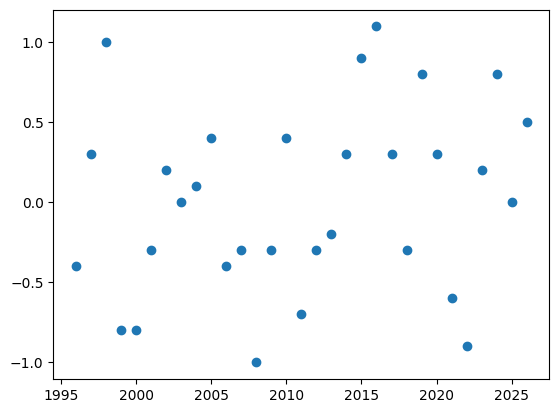

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# adding in ONI index data from https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/oni/v6/
oniYears = np.arange(1996,2027,1)
oniValues = np.array([-0.4,0.3,1,-0.8,-0.8,-0.3,0.2,0,0.1,0.4,-0.4,-0.3,-1,-0.3,0.4,-0.7,-0.3,-0.2,0.3,0.9,1.1,0.3,-0.3,0.8,0.3,-0.6,-0.9,0.2,0.8,0,0.5])
plt.scatter(oniYears,oniValues)


***** plot index vs. cover ratio together in one plot, for covariance!!